
# Task 2: Unemployment Analysis with Python

## 1. Project Identification

This project explores unemployment trends across Indian states and regions using Python, pandas, Matplotlib, and Seaborn. It focuses on understanding how unemployment rates varied over time and across regions, particularly around the COVID-19 pandemic.

## 2. Problem Statement

Unemployment is an important economic and social indicator. Understanding how unemployment rates change across regions and over time can help identify regional disparities and periods of economic disruption. The COVID-19 pandemic and associated lockdowns created a major disruption to economic activity, making this period especially important to investigate.

This project will analyze historical unemployment data from India to identify temporal patterns, compare regional unemployment levels, and examine differences between pre-COVID and COVID-affected periods.

## 3. Project Objectives

- Load and inspect a suitable unemployment dataset for India.
- Assess data quality, missing values, duplicates, and data types.
- Explore regional and monthly unemployment patterns through EDA.
- Compare unemployment rates across Indian states and regions.
- Examine relationships between unemployment, employment, and labour force participation.
- Compare average unemployment rates before and after a defined COVID-19 cutoff.
- Communicate findings through clear visualizations and evidence-based observations.

## 4. Tools and Technologies

- Python
- Google Colab / Jupyter Notebook
- pandas and NumPy
- Matplotlib and Seaborn

## 5. Expected Outcome

A clean, well-documented notebook containing data inspection, statistical summaries, visual analysis, COVID-period comparisons, and conclusions grounded in the available data.

## 6. Scope and Limitation

The analysis will be limited to the time period, regions, and variables available in the selected dataset. Observed changes around the COVID-19 period will be interpreted as associations rather than proof that the pandemic alone caused every change.


In [1]:

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from google.colab import files

# Display and visualization settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully.")
print("pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully.
pandas version: 2.2.3
NumPy version: 2.1.3


DATA COLLECTION

In [2]:

# ============================================================
# 2. DATA COLLECTION — UPLOAD BOTH DATASETS
# ============================================================

from pathlib import Path

print("Please upload BOTH CSV files:")
print("1. Unemployment in India.csv")
print("2. Unemployment_Rate_upto_11_2020.csv")

uploaded = files.upload()

# Identify the two uploaded CSV files
csv_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".csv")
]

if len(csv_files) < 2:
    raise ValueError(
        "Please upload both CSV files before continuing."
    )

print("\nUploaded files:")
for filename in csv_files:
    print("-", filename)

# Identify files by their names
file_lookup = {
    Path(filename).stem.strip().lower(): filename
    for filename in csv_files
}

dataset1_matches = [
    filename for filename in csv_files
    if "unemployment in india" in Path(filename).stem.lower()
]

dataset2_matches = [
    filename for filename in csv_files
    if "unemployment_rate_upto_11_2020" in Path(filename).stem.lower()
]

if not dataset1_matches or not dataset2_matches:
    raise ValueError(
        "Could not identify both expected files. "
        "Check that their filenames match the dataset names."
    )

FILE_INDIA = dataset1_matches[0]
FILE_UPTO_2020 = dataset2_matches[0]

print("\nDataset files identified successfully.")
print("Dataset 1:", FILE_INDIA)
print("Dataset 2:", FILE_UPTO_2020)


Please upload BOTH CSV files:
1. Unemployment in India.csv
2. Unemployment_Rate_upto_11_2020.csv


Saving Unemployment in India.csv to Unemployment in India.csv
Saving Unemployment_Rate_upto_11_2020.csv to Unemployment_Rate_upto_11_2020.csv

Uploaded files:
- Unemployment in India.csv
- Unemployment_Rate_upto_11_2020.csv

Dataset files identified successfully.
Dataset 1: Unemployment in India.csv
Dataset 2: Unemployment_Rate_upto_11_2020.csv


In [3]:

# ============================================================
# 3. LOAD DATASETS
# ============================================================

df_india_raw = pd.read_csv(FILE_INDIA)
df_2020_raw = pd.read_csv(FILE_UPTO_2020)

# Preserve independent working copies
df_india = df_india_raw.copy()
df_2020 = df_2020_raw.copy()

print("Both datasets loaded successfully.")
print(f"Dataset 1 shape: {df_india.shape}")
print(f"Dataset 2 shape: {df_2020.shape}")


Both datasets loaded successfully.
Dataset 1 shape: (768, 7)
Dataset 2 shape: (267, 9)


In [4]:

# ============================================================
# 4. INITIAL DATASET INSPECTION
# ============================================================

for name, data in [
    ("Unemployment in India", df_india),
    ("Unemployment Rate up to November 2020", df_2020)
]:
    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    print("\nShape (rows, columns):", data.shape)

    print("\nColumn names:")
    print(data.columns.tolist())

    print("\nFirst 5 rows:")
    display(data.head())

    print("\nLast 5 rows:")
    display(data.tail())

    print("\nDataset information:")
    data.info()



UNEMPLOYMENT IN INDIA

Shape (rows, columns): (768, 7)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

First 5 rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural



Last 5 rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
767,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB

UNEMPLOYMENT RATE UP TO NOVEMBER 2020

Shape (rows, columns): (267, 9)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' 

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74



Last 5 rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
262,West Bengal,30-06-2020,M,7.29,30726310,40.39,East,22.9868,87.855
263,West Bengal,31-07-2020,M,6.83,35372506,46.17,East,22.9868,87.855
264,West Bengal,31-08-2020,M,14.87,33298644,47.48,East,22.9868,87.855
265,West Bengal,30-09-2020,M,9.35,35707239,47.73,East,22.9868,87.855
266,West Bengal,31-10-2020,M,9.98,33962549,45.63,East,22.9868,87.855



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    267 non-null    object 
 1    Date                                     267 non-null    object 
 2    Frequency                                267 non-null    object 
 3    Estimated Unemployment Rate (%)          267 non-null    float64
 4    Estimated Employed                       267 non-null    int64  
 5    Estimated Labour Participation Rate (%)  267 non-null    float64
 6   Region.1                                  267 non-null    object 
 7   longitude                                 267 non-null    float64
 8   latitude                                  267 non-null    float64
dtypes: float64(4), int64(1), object(4)
memory usage: 18.9+ KB


In [5]:

# ============================================================
# 5. DATA QUALITY CHECKS
# ============================================================

def inspect_data_quality(data, dataset_name):
    print("\n" + "=" * 70)
    print(f"DATA QUALITY: {dataset_name.upper()}")
    print("=" * 70)

    # Missing values
    missing_report = pd.DataFrame({
        "Missing Count": data.isna().sum(),
        "Missing Percentage (%)": (
            data.isna().mean() * 100
        ).round(2)
    })

    print("\nMissing values:")
    display(missing_report)

    # Duplicate records
    print("\nExact duplicate rows:", data.duplicated().sum())

    # Data types
    print("\nData types:")
    display(data.dtypes.rename("Data Type").to_frame())

    # Unique values
    print("\nUnique values per column:")
    display(
        data.nunique(dropna=False)
        .rename("Unique Count")
        .to_frame()
    )

inspect_data_quality(df_india, "Unemployment in India")
inspect_data_quality(df_2020, "Unemployment Rate up to November 2020")



DATA QUALITY: UNEMPLOYMENT IN INDIA

Missing values:


,Missing Count,Missing Percentage (%)
Region,28,3.65
Date,28,3.65
Frequency,28,3.65
Estimated Unemployment Rate (%),28,3.65
Estimated Employed,28,3.65
Estimated Labour Participation Rate (%),28,3.65
Area,28,3.65



Exact duplicate rows: 27

Data types:


,Data Type
Region,object
Date,object
Frequency,object
Estimated Unemployment Rate (%),float64
Estimated Employed,float64
Estimated Labour Participation Rate (%),float64
Area,object



Unique values per column:


...

,Missing Count,Missing Percentage (%)
Region,0,0.0
Date,0,0.0
Frequency,0,0.0
Estimated Unemployment Rate (%),0,0.0
Estimated Employed,0,0.0
Estimated Labour Participation Rate (%),0,0.0
Region.1,0,0.0
longitude,0,0.0
latitude,0,0.0



Exact duplicate rows: 0

Data types:


,Data Type
Region,object
Date,object
Frequency,object
Estimated Unemployment Rate (%),float64
Estimated Employed,int64
Estimated Labour Participation Rate (%),float64
Region.1,object
longitude,float64
latitude,float64



Unique values per column:


,Unique Count
Region,27
Date,10
Frequency,1
Estimated Unemployment Rate (%),252
Estimated Employed,267
Estimated Labour Participation Rate (%),248
Region.1,5
longitude,27
latitude,24


In [6]:

# ============================================================
# 6. BASIC STATISTICAL SUMMARY
# ============================================================

for name, data in [
    ("Unemployment in India", df_india),
    ("Unemployment Rate up to November 2020", df_2020)
]:
    print("\n" + "=" * 70)
    print(f"STATISTICAL SUMMARY: {name.upper()}")
    print("=" * 70)

    print("\nNumerical statistics:")
    display(data.describe().T)

    print("\nSummary of all columns:")
    display(data.describe(include="all").T)



STATISTICAL SUMMARY: UNEMPLOYMENT IN INDIA

Numerical statistics:


,count,mean,std,min,25%,50%,75%,max
Estimated Unemployment Rate (%),740.0,1.178795e+01,1.072130e+01,0.00,4.657500e+00,8.35,1.588750e+01,76.74
Estimated Employed,740.0,7.204460e+06,8.087988e+06,49420.00,1.190404e+06,4744178.50,1.127549e+07,45777509.00
Estimated Labour Participation Rate (%),740.0,4.263012e+01,8.111094e+00,13.33,3.806250e+01,41.16,4.550500e+01,72.57



Summary of all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Region,740,28,Andhra Pradesh,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,740,14,31-10-2019,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Frequency,740,2,Monthly,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),740.0,NaN,NaN,NaN,11.787946,10.721298,0.0,4.6575,8.35,15.8875,76.74
Estimated Employed,740.0,NaN,NaN,NaN,7204460.025676,8087988.429458,49420.0,1190404.5,4744178.5,11275489.5,45777509.0
Estimated Labour Participation Rate (%),740.0,NaN,NaN,NaN,42.630122,8.111094,13.33,38.0625,41.16,45.505,72.57
Area,740,2,Urban,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN



STATISTICAL SUMMARY: UNEMPLOYMENT RATE UP TO NOVEMBER 2020

Numerical statistics:


,count,mean,std,min,25%,50%,75%,max
Estimated Unemployment Rate (%),267.0,1.223693e+01,1.080328e+01,0.5000,4.845000e+00,9.650000e+00,1.675500e+01,7.585000e+01
Estimated Employed,267.0,1.396211e+07,1.336632e+07,117542.0000,2.838930e+06,9.732417e+06,2.187869e+07,5.943376e+07
Estimated Labour Participation Rate (%),267.0,4.168157e+01,7.845419e+00,16.7700,3.726500e+01,4.039000e+01,4.405500e+01,6.969000e+01
longitude,267.0,2.282605e+01,6.270731e+00,10.8505,1.811240e+01,2.361020e+01,2.727840e+01,3.377820e+01
latitude,267.0,8.053242e+01,5.831738e+00,71.1924,7.608560e+01,7.901930e+01,8.527990e+01,9.293760e+01



Summary of all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Region,267,27,Andhra Pradesh,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,267,10,31-05-2020,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Frequency,267,1,M,267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),267.0,NaN,NaN,NaN,12.236929,10.803283,0.5,4.845,9.65,16.755,75.85
Estimated Employed,267.0,NaN,NaN,NaN,13962105.722846,13366318.359733,117542.0,2838930.5,9732417.0,21878686.0,59433759.0
Estimated Labour Participation Rate (%),267.0,NaN,NaN,NaN,41.681573,7.845419,16.77,37.265,40.39,44.055,69.69
Region.1,267,5,North,79,NaN,NaN,NaN,NaN,NaN,NaN,NaN
longitude,267.0,NaN,NaN,NaN,22.826048,6.270731,10.8505,18.1124,23.6102,27.2784,33.7782
latitude,267.0,NaN,NaN,NaN,80.532425,5.831738,71.1924,76.0856,79.0193,85.2799,92.9376


In [7]:

# ============================================================
# 7. INSPECT DATES, REGIONS, AND CATEGORIES
# ============================================================

def prepare_inspection_copy(data):
    result = data.copy()

    # Remove accidental whitespace from column names
    result.columns = result.columns.str.strip()

    # Trim whitespace in text columns
    for column in result.select_dtypes(include=["object", "string"]).columns:
        result[column] = result[column].str.strip()

    return result

inspect_india = prepare_inspection_copy(df_india)
inspect_2020 = prepare_inspection_copy(df_2020)

for name, data in [
    ("Unemployment in India", inspect_india),
    ("Unemployment Rate up to November 2020", inspect_2020)
]:
    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    if "Region" in data.columns:
        print("\nNumber of distinct region names:")
        print(data["Region"].nunique())

        print("\nRegion names:")
        print(sorted(data["Region"].dropna().unique().tolist()))

    if "Date" in data.columns:
        print("\nSample date values as stored:")
        display(data["Date"].head(10).to_frame())

        print("\nNumber of distinct date strings:")
        print(data["Date"].nunique())

    if "Frequency" in data.columns:
        print("\nFrequency categories:")
        display(data["Frequency"].value_counts(dropna=False).to_frame())

    if "Area" in data.columns:
        print("\nArea categories:")
        display(data["Area"].value_counts(dropna=False).to_frame())

    # Some versions of the second dataset have two columns
    # that both represent a region in different ways.
    if "Region" in data.columns:
        print("\nRegion column distinct count:", data["Region"].nunique())

    if "longitude" in data.columns:
        print("\nCoordinate summary:")
        display(data[["longitude", "latitude"]].describe().T)



UNEMPLOYMENT IN INDIA

Number of distinct region names:
28

Region names:
['Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Sample date values as stored:


,Date
0,31-05-2019
1,30-06-2019
2,31-07-2019
3,31-08-2019
4,30-09-2019
5,31-10-2019
6,30-11-2019
7,31-12-2019
8,31-01-2020
9,29-02-2020



Number of distinct date strings:
14

Frequency categories:


,count
Frequency,
Monthly,740
NaN,28



Area categories:


...

,Date
0,31-01-2020
1,29-02-2020
2,31-03-2020
3,30-04-2020
4,31-05-2020
5,30-06-2020
6,31-07-2020
7,31-08-2020
8,30-09-2020
9,31-10-2020



Number of distinct date strings:
10

Frequency categories:


,count
Frequency,
M,267



Region column distinct count: 27

Coordinate summary:


,count,mean,std,min,25%,50%,75%,max
longitude,267.0,22.826048,6.270731,10.8505,18.1124,23.6102,27.2784,33.7782
latitude,267.0,80.532425,5.831738,71.1924,76.0856,79.0193,85.2799,92.9376



## 7. Data Cleaning and Validation

The initial inspection identified whitespace in several column names, 28 entirely missing rows in the first dataset, and different geographic columns in the two datasets.

We will create cleaned working copies, preserve the original raw datasets, remove only completely empty rows, standardize column names and text values, and then recheck duplicates and missing values. Valid observations will not be deleted without investigation.


In [8]:

# ============================================================
# 8. STANDARDIZE DATASETS AND REMOVE EMPTY ROWS
# ============================================================

def clean_structure(data):
    cleaned = data.copy()

    # Standardize column names
    cleaned.columns = cleaned.columns.str.strip()

    # Remove rows where every column is missing
    rows_before = len(cleaned)
    cleaned = cleaned.dropna(how="all").copy()
    empty_rows_removed = rows_before - len(cleaned)

    # Remove accidental whitespace from text values
    for column in cleaned.select_dtypes(
        include=["object", "string"]
    ).columns:
        cleaned[column] = cleaned[column].str.strip()

    # Reset row numbering after cleaning
    cleaned.reset_index(drop=True, inplace=True)

    return cleaned, empty_rows_removed


df_india, empty_rows_india = clean_structure(df_india_raw)
df_2020, empty_rows_2020 = clean_structure(df_2020_raw)

print("Structural cleaning completed.")
print(f"Dataset 1: removed {empty_rows_india} completely empty rows.")
print(f"Dataset 2: removed {empty_rows_2020} completely empty rows.")

print("\nDataset 1 shape after cleaning:", df_india.shape)
print("Dataset 2 shape after cleaning:", df_2020.shape)

print("\nDataset 1 standardized columns:")
print(df_india.columns.tolist())

print("\nDataset 2 standardized columns:")
print(df_2020.columns.tolist())


Structural cleaning completed.
Dataset 1: removed 28 completely empty rows.
Dataset 2: removed 0 completely empty rows.

Dataset 1 shape after cleaning: (740, 7)
Dataset 2 shape after cleaning: (267, 9)

Dataset 1 standardized columns:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Dataset 2 standardized columns:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']


In [9]:

# ============================================================
# 9. RECHECK DATA QUALITY AFTER STRUCTURAL CLEANING
# ============================================================

for name, data in [
    ("Unemployment in India", df_india),
    ("Unemployment Rate up to November 2020", df_2020)
]:
    print("\n" + "=" * 65)
    print(name.upper())
    print("=" * 65)

    print("\nShape:", data.shape)
    print("\nMissing values by column:")
    display(data.isna().sum().rename("Missing Count").to_frame())

    print("\nExact duplicate rows:", data.duplicated().sum())

    # Check duplicates using likely observation identifiers
    if {"Region", "Date", "Area"}.issubset(data.columns):
        print(
            "Duplicate Region-Date-Area combinations:",
            data.duplicated(
                subset=["Region", "Date", "Area"]
            ).sum()
        )

    elif {"Region", "Date"}.issubset(data.columns):
        print(
            "Duplicate Region-Date combinations:",
            data.duplicated(
                subset=["Region", "Date"]
            ).sum()
        )



UNEMPLOYMENT IN INDIA

Shape: (740, 7)

Missing values by column:


,Missing Count
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0



Exact duplicate rows: 0
Duplicate Region-Date-Area combinations: 0

UNEMPLOYMENT RATE UP TO NOVEMBER 2020

Shape: (267, 9)

Missing values by column:


,Missing Count
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Region.1,0
longitude,0
latitude,0



Exact duplicate rows: 0
Duplicate Region-Date combinations: 0



## 8. Date Conversion and Type Validation

The date values use a day-month-year format. We will convert them to pandas datetime values so the datasets can later be sorted chronologically, grouped by month, and compared across the COVID-19 period.

We will also verify that the unemployment rate, estimated employment, and labour participation rate are numeric.


In [10]:

# ============================================================
# 10. CONVERT DATES AND VALIDATE DATA TYPES
# ============================================================

date_column = "Date"

numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for name, data in [
    ("Unemployment in India", df_india),
    ("Unemployment Rate up to November 2020", df_2020)
]:
    # Parse dates using day-month-year format
    data[date_column] = pd.to_datetime(
        data[date_column],
        format="%d-%m-%Y",
        errors="coerce"
    )

    # Convert numeric columns safely
    for column in numeric_columns:
        data[column] = pd.to_numeric(
            data[column],
            errors="coerce"
        )

    print("\n" + "=" * 65)
    print(name.upper())
    print("=" * 65)

    print("\nData types after conversion:")
    display(data.dtypes.rename("Data Type").to_frame())

    print("\nInvalid or missing dates:", data[date_column].isna().sum())

    print("\nDate range:")
    print("Earliest:", data[date_column].min())
    print("Latest:  ", data[date_column].max())

    print("\nMissing values after conversion:")
    display(data.isna().sum().rename("Missing Count").to_frame())

    print("\nNumeric values that are negative:")
    display(
        (data[numeric_columns] < 0).sum()
        .rename("Negative Count")
        .to_frame()
    )



UNEMPLOYMENT IN INDIA

Data types after conversion:


,Data Type
Region,object
Date,datetime64[ns]
Frequency,object
Estimated Unemployment Rate (%),float64
Estimated Employed,float64
Estimated Labour Participation Rate (%),float64
Area,object



Invalid or missing dates: 0

Date range:
Earliest: 2019-05-31 00:00:00
Latest:   2020-06-30 00:00:00

Missing values after conversion:


,Missing Count
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0



Numeric values that are negative:


...

,Data Type
Region,object
Date,datetime64[ns]
Frequency,object
Estimated Unemployment Rate (%),float64
Estimated Employed,int64
Estimated Labour Participation Rate (%),float64
Region.1,object
longitude,float64
latitude,float64



Invalid or missing dates: 0

Date range:
Earliest: 2020-01-31 00:00:00
Latest:   2020-10-31 00:00:00

Missing values after conversion:


,Missing Count
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Region.1,0
longitude,0
latitude,0



Numeric values that are negative:


,Negative Count
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0


In [11]:

# ============================================================
# 11. FINAL DATASET INSPECTION SUMMARY
# ============================================================

summary_rows = []

for name, data in [
    ("Unemployment in India", df_india),
    ("Unemployment Rate up to November 2020", df_2020)
]:
    summary_rows.append({
        "Dataset": name,
        "Rows": len(data),
        "Columns": len(data.columns),
        "Regions": data["Region"].nunique(),
        "Start Date": data["Date"].min(),
        "End Date": data["Date"].max(),
        "Missing Cells": int(data.isna().sum().sum()),
        "Exact Duplicate Rows": int(data.duplicated().sum())
    })

dataset_summary = pd.DataFrame(summary_rows)

display(dataset_summary)

print("\nDataset 1 frequency values:")
display(df_india["Frequency"].value_counts(dropna=False).to_frame())

print("\nDataset 2 frequency values:")
display(df_2020["Frequency"].value_counts(dropna=False).to_frame())

print("\nDataset 1 area values:")
display(df_india["Area"].value_counts(dropna=False).to_frame())

print("\nDataset 2 broader regional classifications:")
display(df_2020["Region.1"].value_counts(dropna=False).to_frame())


,Dataset,Rows,Columns,Regions,Start Date,End Date,Missing Cells,Exact Duplicate Rows
0,Unemployment in India,740,7,28,2019-05-31,2020-06-30,0,0
1,Unemployment Rate up to November 2020,267,9,27,2020-01-31,2020-10-31,0,0



Dataset 1 frequency values:


,count
Frequency,
Monthly,740



Dataset 2 frequency values:


,count
Frequency,
M,267



Dataset 1 area values:


,count
Area,
Urban,381
Rural,359



Dataset 2 broader regional classifications:


,count
Region.1,
North,79
South,60
West,50
East,40
Northeast,38


EDA

In [12]:

# Create analysis copies
eda_india = df_india.copy()
eda_2020 = df_2020.copy()

# Derived time features for Dataset 1
eda_india["YearMonth"] = eda_india["Date"].dt.to_period("M").astype(str)
eda_india["Year"] = eda_india["Date"].dt.year
eda_india["Month"] = eda_india["Date"].dt.month

# Define the comparison period for COVID-era analysis
eda_india["Period"] = np.where(
    eda_india["Date"] < pd.Timestamp("2020-03-01"),
    "Before March 2020",
    "March 2020 onward"
)

# Standardize Dataset 2's broad region column name
eda_2020 = eda_2020.rename(columns={"Region.1": "Macro_Region"})
eda_2020["YearMonth"] = eda_2020["Date"].dt.to_period("M").astype(str)

print("Dataset 1 analysis shape:", eda_india.shape)
print("Dataset 2 analysis shape:", eda_2020.shape)

print("\nDataset 1 unemployment statistics:")
display(
    eda_india["Estimated Unemployment Rate (%)"]
    .describe()
    .to_frame("Value")
    .round(2)
)

print("\nRecords per month in Dataset 1:")
display(eda_india.groupby("YearMonth").size().to_frame("Records"))

print("\nUnique regions:", eda_india["Region"].nunique())
print("Area categories:", eda_india["Area"].unique())


Dataset 1 analysis shape: (740, 11)
Dataset 2 analysis shape: (267, 10)

Dataset 1 unemployment statistics:


,Value
count,740.00
mean,11.79
std,10.72
min,0.00
25%,4.66
50%,8.35
75%,15.89
max,76.74



Records per month in Dataset 1:


,Records
YearMonth,
2019-05,54
2019-06,54
2019-07,54
2019-08,53
2019-09,52
2019-10,55
2019-11,55
2019-12,53
2020-01,53



Unique regions: 28
Area categories: ['Rural' 'Urban']


Monthly unemployment trend

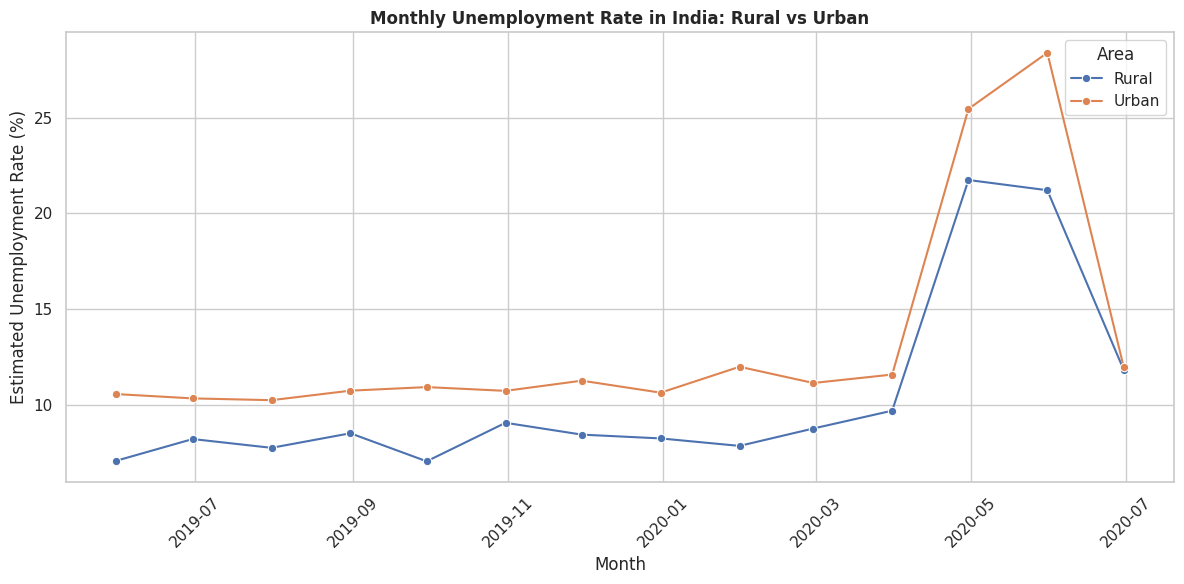

In [13]:

monthly_trend = (
    eda_india.groupby(["Date", "Area"])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_trend,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Area",
    marker="o"
)

plt.title("Monthly Unemployment Rate in India: Rural vs Urban")
plt.xlabel("Month")
plt.ylabel("Estimated Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Compare average unemployment by state/region

10 regions with the highest average unemployment:


,Average Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


10 regions with the lowest average unemployment:


,Average Unemployment Rate (%)
Region,
Meghalaya,4.80
Odisha,5.66
Assam,6.43
Uttarakhand,6.58
Gujarat,6.66
Karnataka,6.68
Sikkim,7.25
Madhya Pradesh,7.41
Andhra Pradesh,7.48


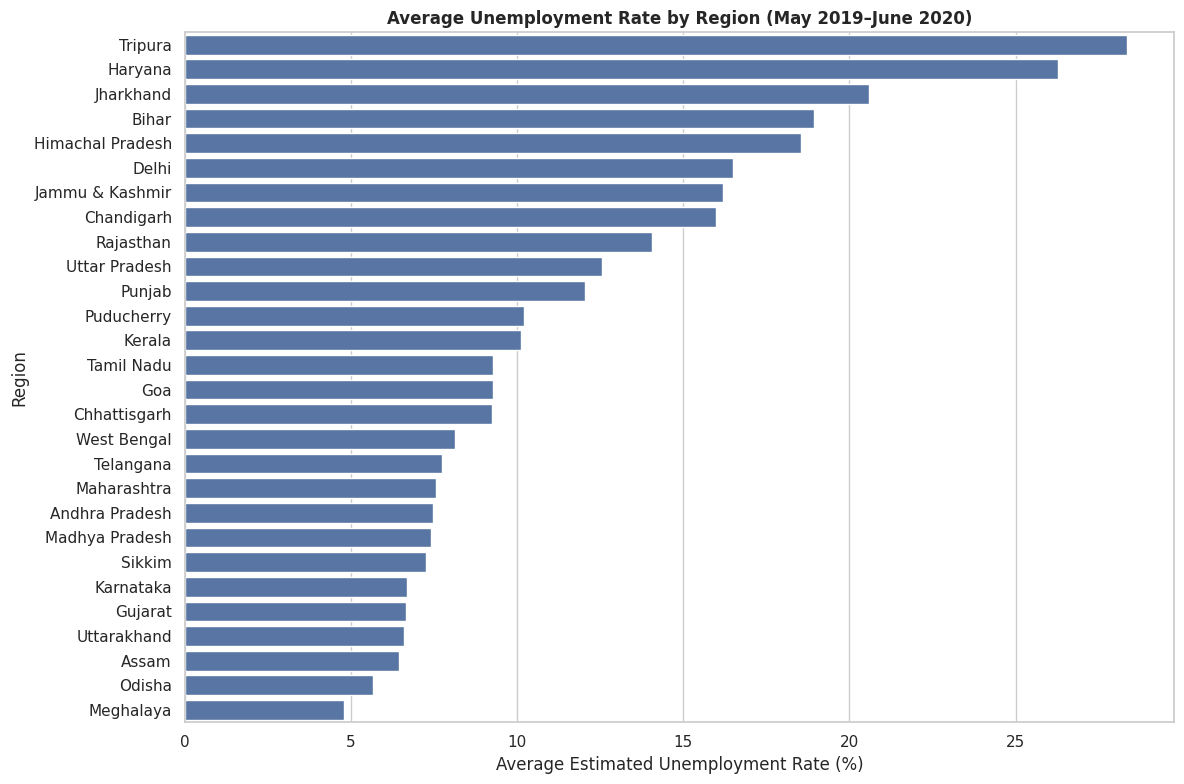

In [14]:

region_avg = (
    eda_india.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print("10 regions with the highest average unemployment:")
display(region_avg.head(10).round(2).to_frame("Average Unemployment Rate (%)"))

print("10 regions with the lowest average unemployment:")
display(region_avg.tail(10).sort_values().round(2).to_frame("Average Unemployment Rate (%)"))

plt.figure(figsize=(12, 8))
sns.barplot(
    x=region_avg.values,
    y=region_avg.index
)
plt.title("Average Unemployment Rate by Region (May 2019–June 2020)")
plt.xlabel("Average Estimated Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


Compare unemployment distributions in rural and urban areas

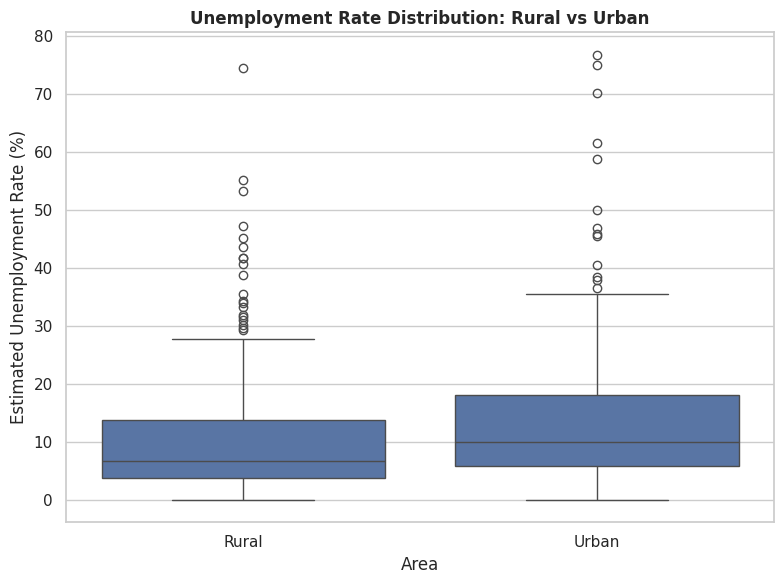

Average unemployment rate by area:


,mean,median,std,min,max
Area,,,,,
Rural,10.32,6.76,10.04,0.0,74.51
Urban,13.17,9.97,11.17,0.0,76.74


In [15]:

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=eda_india,
    x="Area",
    y="Estimated Unemployment Rate (%)"
)

plt.title("Unemployment Rate Distribution: Rural vs Urban")
plt.xlabel("Area")
plt.ylabel("Estimated Unemployment Rate (%)")
plt.tight_layout()
plt.show()

print("Average unemployment rate by area:")
display(
    eda_india.groupby("Area")["Estimated Unemployment Rate (%)"]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)


Explore relationships between the numeric variables

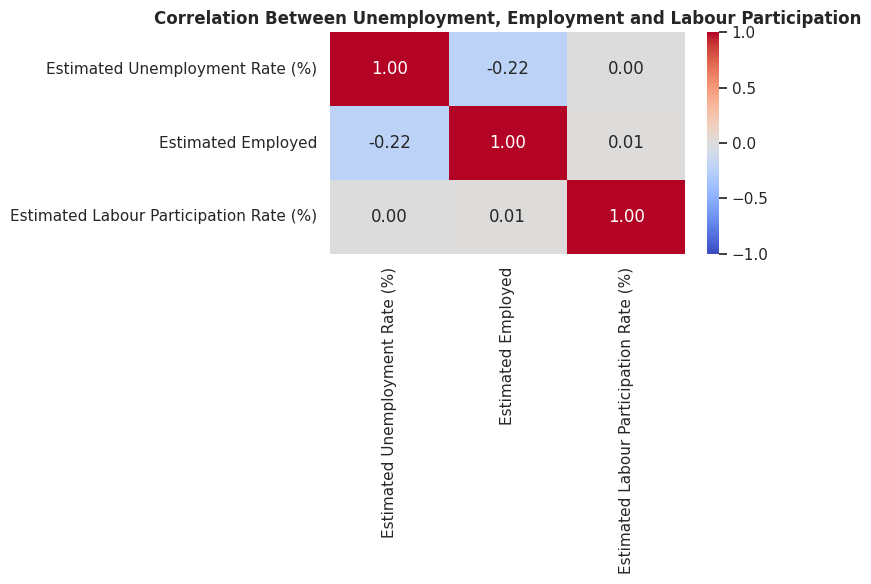

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000,-0.223,0.003
Estimated Employed,-0.223,1.000,0.011
Estimated Labour Participation Rate (%),0.003,0.011,1.000


In [16]:

numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation = eda_india[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Unemployment, Employment and Labour Participation")
plt.tight_layout()
plt.show()

display(correlation.round(3))


Compare before and during the COVID-19 period

Average unemployment by period and area:


mean  median  count
Period            Area                       
Before March 2020 Rural   8.09    5.79    260
                  Urban  10.84    7.88    276
March 2020 onward Rural  16.18   12.50     99
                  Urban  19.28   15.22    105

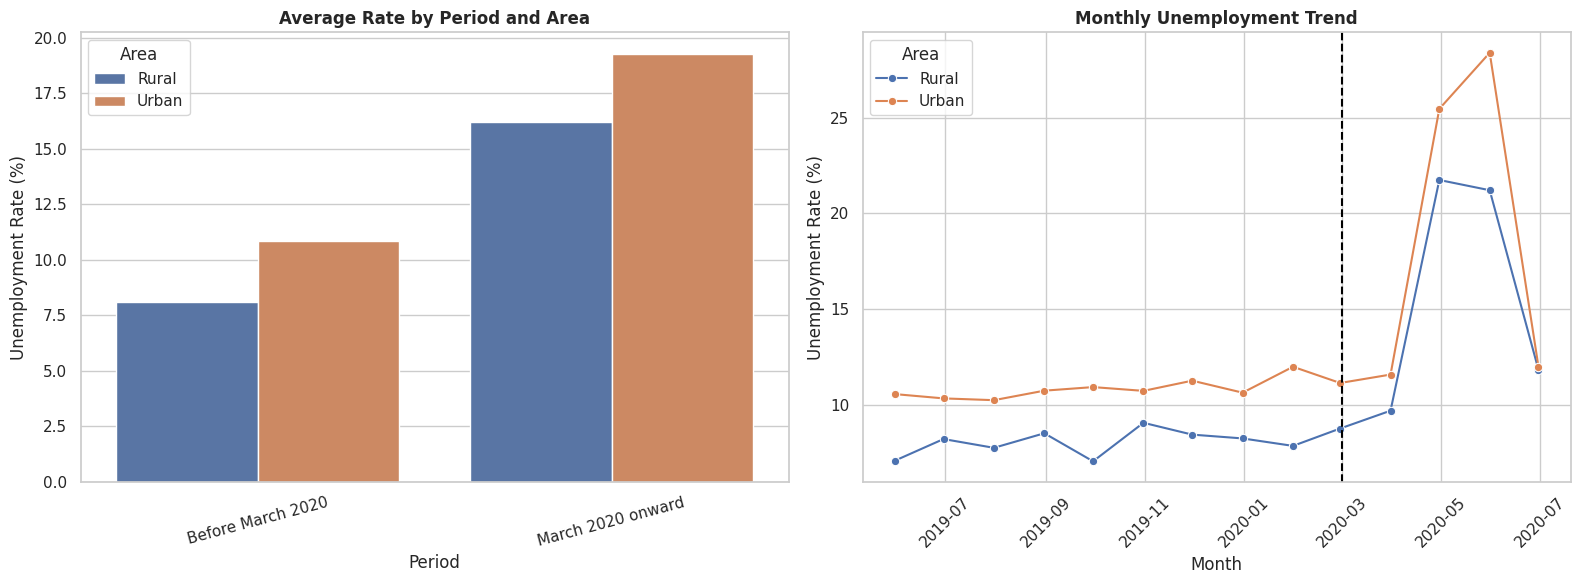

In [18]:

# COVID-period comparison: summary by area
covid_comparison = (
    eda_india.groupby(["Period", "Area"])["Estimated Unemployment Rate (%)"]
    .agg(["mean", "median", "count"])
    .round(2)
)

print("Average unemployment by period and area:")
display(covid_comparison)

# Monthly average, separated by rural and urban areas
monthly_covid = (
    eda_india.groupby(["Date", "Area"])["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=eda_india,
    x="Period",
    y="Estimated Unemployment Rate (%)",
    hue="Area",
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Average Rate by Period and Area")
axes[0].set_xlabel("Period")
axes[0].set_ylabel("Unemployment Rate (%)")
axes[0].tick_params(axis="x", rotation=15)

sns.lineplot(
    data=monthly_covid,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Area",
    marker="o",
    ax=axes[1]
)
axes[1].axvline(
    pd.Timestamp("2020-03-01"),
    linestyle="--",
    color="black",
    label="March 2020 cutoff"
)
axes[1].set_title("Monthly Unemployment Trend")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Unemployment Rate (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


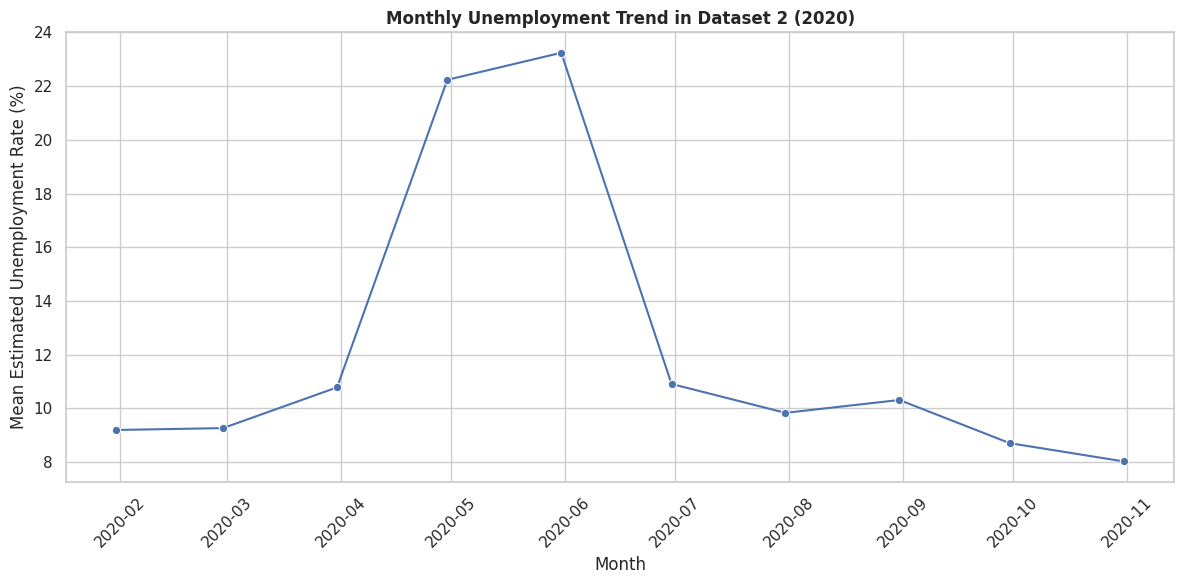

Monthly unemployment averages in Dataset 2:


,Date,Estimated Unemployment Rate (%)
0,2020-01-31,9.20
1,2020-02-29,9.27
2,2020-03-31,10.78
3,2020-04-30,22.24
4,2020-05-31,23.24
5,2020-06-30,10.91
6,2020-07-31,9.83
7,2020-08-31,10.31
8,2020-09-30,8.71
9,2020-10-31,8.03


Average unemployment by broad region classification:


,Average Rate (%)
Macro_Region,
North,15.89
East,13.92
Northeast,10.95
South,10.45
West,8.24


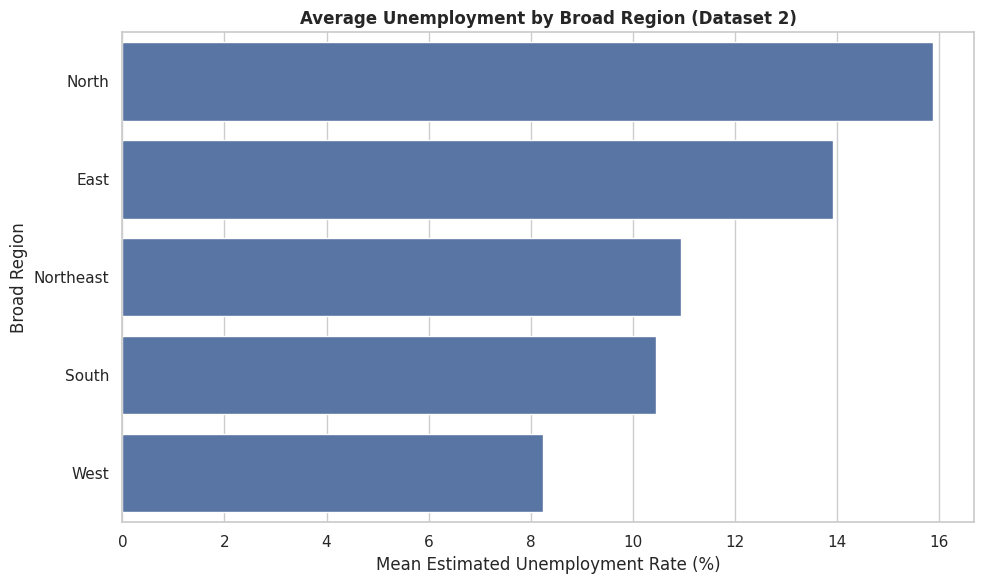

In [19]:

# Dataset 2: monthly national-sample average across available regional records
monthly_2020 = (
    eda_2020.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_2020,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    marker="o"
)

plt.title("Monthly Unemployment Trend in Dataset 2 (2020)")
plt.xlabel("Month")
plt.ylabel("Mean Estimated Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Monthly unemployment averages in Dataset 2:")
display(monthly_2020.round(2))

# Average by broad region classification
macro_region_avg = (
    eda_2020.groupby("Macro_Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print("Average unemployment by broad region classification:")
display(macro_region_avg.round(2).to_frame("Average Rate (%)"))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=macro_region_avg.values,
    y=macro_region_avg.index
)
plt.title("Average Unemployment by Broad Region (Dataset 2)")
plt.xlabel("Mean Estimated Unemployment Rate (%)")
plt.ylabel("Broad Region")
plt.tight_layout()
plt.show()


Preprocessing and model plan

Build forecasting features

In [20]:

# Work from the cleaned primary dataset
model_data = df_india.copy()

model_data = model_data.sort_values(
    ["Region", "Area", "Date"]
).reset_index(drop=True)

group_keys = ["Region", "Area"]
unemployment_col = "Estimated Unemployment Rate (%)"
employed_col = "Estimated Employed"
participation_col = "Estimated Labour Participation Rate (%)"

# Historical values available before the month being predicted
model_data["Lag1_Unemployment"] = (
    model_data.groupby(group_keys)[unemployment_col].shift(1)
)
model_data["Lag2_Unemployment"] = (
    model_data.groupby(group_keys)[unemployment_col].shift(2)
)
model_data["Lag1_Employed"] = (
    model_data.groupby(group_keys)[employed_col].shift(1)
)
model_data["Lag1_Labour_Participation"] = (
    model_data.groupby(group_keys)[participation_col].shift(1)
)

# Calendar features for the month being predicted
model_data["Year"] = model_data["Date"].dt.year
model_data["Month"] = model_data["Date"].dt.month

# Drop rows without the required historical values
model_data = model_data.dropna(
    subset=[
        "Lag1_Unemployment",
        "Lag2_Unemployment",
        "Lag1_Employed",
        "Lag1_Labour_Participation",
        unemployment_col
    ]
).reset_index(drop=True)

print("Model dataset shape:", model_data.shape)
print("Model date range:", model_data["Date"].min(), "to", model_data["Date"].max())
print("\nMissing values in model dataset:")
display(model_data.isna().sum().to_frame("Missing Values"))

display(model_data.head())


Model dataset shape: (630, 13)
Model date range: 2019-07-31 00:00:00 to 2020-06-30 00:00:00

Missing values in model dataset:


,Missing Values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0
Lag1_Unemployment,0
Lag2_Unemployment,0
Lag1_Employed,0


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Lag1_Unemployment,Lag2_Unemployment,Lag1_Employed,Lag1_Labour_Participation,Year,Month
0,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural,3.05,3.65,11755881.0,42.05,2019,7
1,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural,3.75,3.05,12086707.0,43.50,2019,8
2,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural,3.32,3.75,12285693.0,43.97,2019,9
3,Andhra Pradesh,2019-10-31,Monthly,3.52,12017412.0,43.01,Rural,5.17,3.32,12256762.0,44.68,2019,10
4,Andhra Pradesh,2019-11-30,Monthly,4.12,11397681.0,41.00,Rural,3.52,5.17,12017412.0,43.01,2019,11


Time-based train/test split

In [21]:

# Features available before or at the forecast calendar period
numeric_features = [
    "Year",
    "Month",
    "Lag1_Unemployment",
    "Lag2_Unemployment",
    "Lag1_Employed",
    "Lag1_Labour_Participation"
]

categorical_features = ["Region", "Area"]
feature_columns = numeric_features + categorical_features

# Hold out the final two calendar months
test_start = pd.Timestamp("2020-05-01")

train_data = model_data[model_data["Date"] < test_start].copy()
test_data = model_data[model_data["Date"] >= test_start].copy()

X_train = train_data[feature_columns].copy()
y_train = train_data[unemployment_col].copy()

X_test = test_data[feature_columns].copy()
y_test = test_data[unemployment_col].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", train_data["Date"].min(), "to", train_data["Date"].max())
print("Testing period:", test_data["Date"].min(), "to", test_data["Date"].max())

if train_data.empty or test_data.empty:
    raise ValueError("The time-based split produced an empty train or test set.")

print("\nTraining dates:", sorted(train_data["Date"].unique()))
print("Testing dates:", sorted(test_data["Date"].unique()))


Training rows: 529
Testing rows: 101
Training period: 2019-07-31 00:00:00 to 2020-04-30 00:00:00
Testing period: 2020-05-31 00:00:00 to 2020-06-30 00:00:00

Training dates: [Timestamp('2019-07-31 00:00:00'), Timestamp('2019-08-31 00:00:00'), Timestamp('2019-09-30 00:00:00'), Timestamp('2019-10-31 00:00:00'), Timestamp('2019-11-30 00:00:00'), Timestamp('2019-12-31 00:00:00'), Timestamp('2020-01-31 00:00:00'), Timestamp('2020-02-29 00:00:00'), Timestamp('2020-03-31 00:00:00'), Timestamp('2020-04-30 00:00:00')]
Testing dates: [Timestamp('2020-05-31 00:00:00'), Timestamp('2020-06-30 00:00:00')]


In [22]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Numeric preprocessing: impute missing values, then scale
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: impute and one-hot encode
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Candidate 1: Ridge Regression
ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

# Candidate 2: Random Forest Regression
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

print("Preprocessing and model pipelines created successfully.")


Preprocessing and model pipelines created successfully.


Cross-validation and hyperparameter tuning

In [23]:

# Create chronological CV folds based on unique training dates
unique_train_dates = np.array(
    sorted(train_data["Date"].unique())
)

if len(unique_train_dates) < 6:
    raise ValueError(
        "Too few training months for the planned time-series cross-validation."
    )

time_splitter = TimeSeriesSplit(n_splits=3)
cv_splits = []

for train_date_idx, val_date_idx in time_splitter.split(unique_train_dates):
    cv_train_dates = unique_train_dates[train_date_idx]
    cv_val_dates = unique_train_dates[val_date_idx]

    fold_train_idx = np.flatnonzero(
        train_data["Date"].isin(cv_train_dates).to_numpy()
    )
    fold_val_idx = np.flatnonzero(
        train_data["Date"].isin(cv_val_dates).to_numpy()
    )

    cv_splits.append((fold_train_idx, fold_val_idx))

print("Chronological cross-validation folds:")
for fold_num, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    print(
        f"Fold {fold_num}: "
        f"{train_data.iloc[train_idx]['Date'].min().date()} to "
        f"{train_data.iloc[train_idx]['Date'].max().date()} "
        f"-> validation "
        f"{train_data.iloc[val_idx]['Date'].min().date()} to "
        f"{train_data.iloc[val_idx]['Date'].max().date()}"
    )

# Hyperparameter grids
ridge_grid = {
    "model__alpha": [0.1, 1.0, 10.0, 100.0]
}

rf_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_leaf": [1, 3]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_grid,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    n_jobs=-1,
    refit=True
)

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_grid,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    n_jobs=-1,
    refit=True
)

ridge_search.fit(X_train, y_train)
rf_search.fit(X_train, y_train)

print("\nRidge best parameters:", ridge_search.best_params_)
print("Ridge CV MAE:", round(-ridge_search.best_score_, 3))

print("\nRandom Forest best parameters:", rf_search.best_params_)
print("Random Forest CV MAE:", round(-rf_search.best_score_, 3))


Chronological cross-validation folds:
Fold 1: 2019-07-31 to 2019-10-31 -> validation 2019-11-30 to 2019-12-31
Fold 2: 2019-07-31 to 2019-12-31 -> validation 2020-01-31 to 2020-02-29
Fold 3: 2019-07-31 to 2020-02-29 -> validation 2020-03-31 to 2020-04-30

Ridge best parameters: {'model__alpha': 0.1}
Ridge CV MAE: 4.836

Random Forest best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Random Forest CV MAE: 4.905


Evaluate against a baseline

In [25]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.base import clone

def make_preprocessor():
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ])

def make_pipeline(model):
    return Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("model", model)
    ])

# Pipelines used later for hyperparameter tuning
ridge_pipeline = make_pipeline(Ridge())

rf_pipeline = make_pipeline(
    RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1
    )
)

print("Independent preprocessing and model pipelines created successfully.")


Independent preprocessing and model pipelines created successfully.


In [26]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline: predicts the mean target from the training data
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

# Train an initial Ridge Regression model
ridge_initial = make_pipeline(Ridge())
ridge_initial.fit(X_train, y_train)
ridge_initial_pred = ridge_initial.predict(X_test)

# Train an initial Random Forest Regression model
rf_initial = make_pipeline(
    RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)
rf_initial.fit(X_train, y_train)
rf_initial_pred = rf_initial.predict(X_test)

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

initial_results = pd.DataFrame([
    {"Model": "Mean Baseline", **calculate_metrics(y_test, baseline_pred)},
    {"Model": "Ridge (Initial)", **calculate_metrics(y_test, ridge_initial_pred)},
    {"Model": "Random Forest (Initial)", **calculate_metrics(y_test, rf_initial_pred)}
]).set_index("Model")

print("Initial model comparison on the held-out test set:")
display(initial_results.round(3))


Initial model comparison on the held-out test set:


,MAE,RMSE,R2
Model,,,
Mean Baseline,11.054,16.094,-0.266
Ridge (Initial),10.497,13.798,0.069
Random Forest (Initial),12.115,15.711,-0.206


Model comparison on the May–June 2020 test period:


,MAE,RMSE,R2
Model,,,
Ridge (Tuned),9.848,13.183,0.151
Ridge (Initial),10.497,13.798,0.069
Mean Baseline,11.054,16.094,-0.266
Random Forest (Initial),12.115,15.711,-0.206
Random Forest (Tuned),12.142,15.737,-0.210



Cross-validation MAE:
Ridge: 4.836
Random Forest: 4.905

Selected model: Ridge
Best parameters: {'model__alpha': 0.1}


,Date,Region,Area,Actual Rate (%),Predicted Rate (%),Absolute Error
10,2020-05-31,Andhra Pradesh,Rural,14.46,12.71,1.75
11,2020-06-30,Andhra Pradesh,Rural,0.85,13.03,12.18
22,2020-05-31,Andhra Pradesh,Urban,24.91,17.25,7.66
23,2020-06-30,Andhra Pradesh,Urban,5.86,16.50,10.64
32,2020-05-31,Assam,Rural,9.38,9.83,0.45
33,2020-06-30,Assam,Rural,0.00,11.07,11.07
44,2020-05-31,Assam,Urban,10.77,13.43,2.66
45,2020-06-30,Assam,Urban,3.42,14.64,11.22
56,2020-05-31,Bihar,Rural,47.26,24.66,22.60
57,2020-06-30,Bihar,Rural,20.49,25.36,4.87


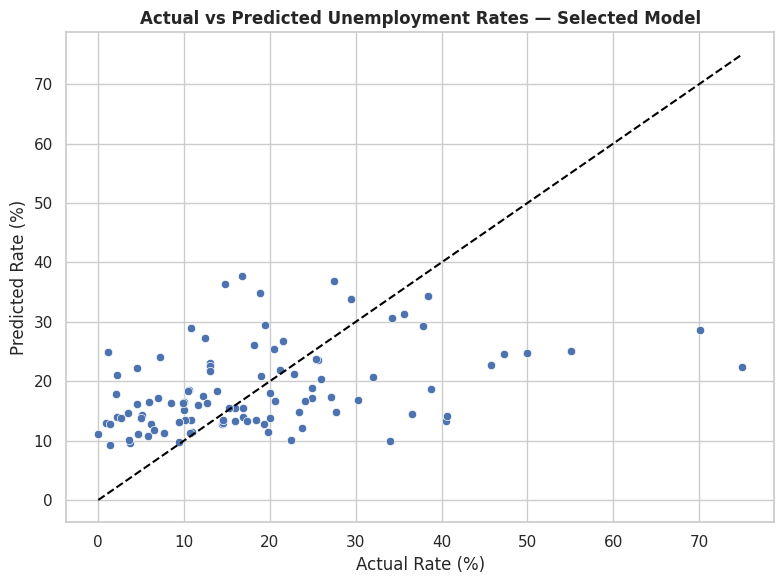

In [30]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

# Select the tuned model using CV score only
searches = [ridge_search, rf_search]
best_search = max(searches, key=lambda search: search.best_score_)
best_pipeline = best_search.best_estimator_

# Predictions from all models
baseline_pred = baseline_model.predict(X_test)
ridge_initial_pred = ridge_initial.predict(X_test)
rf_initial_pred = rf_initial.predict(X_test)
ridge_tuned_pred = ridge_search.best_estimator_.predict(X_test)
rf_tuned_pred = rf_search.best_estimator_.predict(X_test)

all_results = pd.DataFrame([
    {"Model": "Mean Baseline", **calculate_metrics(y_test, baseline_pred)},
    {"Model": "Ridge (Initial)", **calculate_metrics(y_test, ridge_initial_pred)},
    {"Model": "Random Forest (Initial)", **calculate_metrics(y_test, rf_initial_pred)},
    {"Model": "Ridge (Tuned)", **calculate_metrics(y_test, ridge_tuned_pred)},
    {"Model": "Random Forest (Tuned)", **calculate_metrics(y_test, rf_tuned_pred)}
]).set_index("Model")

print("Model comparison on the May–June 2020 test period:")
display(all_results.sort_values("MAE").round(3))

print("\nCross-validation MAE:")
print(f"Ridge: {-ridge_search.best_score_:.3f}")
print(f"Random Forest: {-rf_search.best_score_:.3f}")

print("\nSelected model:", type(best_pipeline.named_steps["model"]).__name__)
print("Best parameters:", best_search.best_params_)

best_predictions = best_pipeline.predict(X_test)

prediction_results = test_data[["Date", "Region", "Area"]].copy()
prediction_results["Actual Rate (%)"] = y_test.to_numpy()
prediction_results["Predicted Rate (%)"] = best_predictions
prediction_results["Absolute Error"] = np.abs(
    prediction_results["Actual Rate (%)"]
    - prediction_results["Predicted Rate (%)"]
)

display(prediction_results.head(20).round(2))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=best_predictions)

lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())
plt.plot([lower, upper], [lower, upper], "--", color="black")

plt.title("Actual vs Predicted Unemployment Rates — Selected Model")
plt.xlabel("Actual Rate (%)")
plt.ylabel("Predicted Rate (%)")
plt.tight_layout()
plt.show()


In [31]:

import joblib
import json
from google.colab import files

MODEL_PATH = "unemployment_forecasting_pipeline.joblib"
METADATA_PATH = "unemployment_forecasting_metadata.json"
PREDICTIONS_PATH = "unemployment_test_predictions.csv"

# Save the fitted preprocessing + model pipeline
joblib.dump(best_pipeline, MODEL_PATH)

# Save metadata and evaluation information
metadata = {
    "project": "Unemployment Analysis with Python",
    "task_type": "Supervised regression / one-step-ahead forecasting experiment",
    "target": unemployment_col,
    "features": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "selected_model": type(best_pipeline.named_steps["model"]).__name__,
    "best_parameters": best_search.best_params_,
    "best_cv_mae": float(-best_search.best_score_),
    "train_start": str(train_data["Date"].min().date()),
    "train_end": str(train_data["Date"].max().date()),
    "test_start": str(test_data["Date"].min().date()),
    "test_end": str(test_data["Date"].max().date()),
    "test_metrics": {
        metric: float(value)
        for metric, value in calculate_metrics(y_test, best_predictions).items()
    },
    "limitation": (
        "Short historical dataset; test period covers May-June 2020. "
        "Forecasting performance may not generalize to other periods."
    )
}

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

# Save the actual-versus-predicted table for documentation
prediction_results.to_csv(PREDICTIONS_PATH, index=False)

print("Saved pipeline:", MODEL_PATH)
print("Saved metadata:", METADATA_PATH)
print("Saved test predictions:", PREDICTIONS_PATH)

# Download all three artifacts from Colab
files.download(MODEL_PATH)
files.download(METADATA_PATH)
files.download(PREDICTIONS_PATH)


Saved pipeline: unemployment_forecasting_pipeline.joblib
Saved metadata: unemployment_forecasting_metadata.json
Saved test predictions: unemployment_test_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:

# Reload the saved pipeline
loaded_pipeline = joblib.load(MODEL_PATH)

# Check that reloaded predictions match the original predictions
reloaded_predictions = loaded_pipeline.predict(X_test)

assert np.allclose(
    best_predictions,
    reloaded_predictions
), "Saved pipeline predictions do not match!"

print("Pipeline loaded successfully.")
print("Verification passed: predictions match the original pipeline.")
print("Selected model:", type(loaded_pipeline.named_steps["model"]).__name__)


Pipeline loaded successfully.
Verification passed: predictions match the original pipeline.
Selected model: Ridge
